# 1 · Healthcare


Presenter: Zhou Dianfeng

Original data file `data/healthcare_2010_2025.csv` is now read from `Healthcare_Data.csv` with identical values.

Data: `Healthcare_Data.csv` (this member's columns of the group dataset).

In [1]:
from pathlib import Path
import os
import pandas as pd

# Locate this member's folder (the folder that contains Healthcare_Data.csv).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Healthcare_Data.csv').is_file())
COMBINED = pd.read_csv(ROOT / 'Healthcare_Data.csv', float_precision='round_trip')

# Each section reads its own columns from the one combined dataset, under the column names its code expects.
SECTIONS = {
    'healthcare': dict(years=(2010, 2025), integer=['year', 'resident_live_births_number'], columns={
        'Year': 'year', 'TFR': 'tfr_per_female',
        'resident_live_births_number': 'resident_live_births_number',
        'cpi_health_2024_100': 'cpi_health_2024_100',
        'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2024_100',
        'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2024_100',
        'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2024_100',
        'cpi_other_health_services_2024_100': 'cpi_other_health_services_2024_100',
        'cpi_health_insurance_2024_100': 'cpi_health_insurance_2024_100',
        'cpi_polyclinic_fees_2024_100': 'cpi_polyclinic_fees_2024_100',
        'cpi_gp_fees_2024_100': 'cpi_gp_fees_2024_100',
        'cpi_specialist_outpatient_fees_2024_100': 'cpi_specialist_outpatient_fees_2024_100',
        'gov_health_development_sgd_million': 'gov_health_development_sgd_million',
        'gov_health_operating_sgd_million': 'gov_health_operating_sgd_million',
        'doctors_per_10000_total_population': 'doctors_per_10000_total_population',
        'nurses_per_10000_total_population': 'nurses_per_10000_total_population',
        'acute_hospital_beds_total_number': 'acute_hospital_beds_total_number',
        'acute_hospital_beds_public_number': 'acute_hospital_beds_public_number',
        'acute_hospital_beds_nonprofit_number': 'acute_hospital_beds_nonprofit_number',
        'acute_hospital_beds_private_number': 'acute_hospital_beds_private_number',
        'acute_hospitals_public_number': 'acute_hospitals_public_number',
        'acute_hospitals_private_number': 'acute_hospitals_private_number',
        'public_polyclinics_number': 'public_polyclinics_number',
        'young_children_health_inflation_2019base_pct': 'young_children_health_inflation_2019base_pct',
        'general_households_health_inflation_2019base_pct': 'general_households_health_inflation_2019base_pct',
        'Gov_Health_per_Capita': 'gov_health_per_capita_sgd',
        'Gov_Health_Total': 'gov_health_expenditure_sgd_million',
        'Gov_Health_%_GDP': 'gov_health_expenditure_gdp_pct',
        'HES_Health_Monthly': 'hes_all_households_health_monthly_sgd',
        'HES_Health_Share_%': 'hes_all_households_health_share_pct'},
        order=['year',
               'tfr_per_female',
               'resident_live_births_number',
               'cpi_health_2024_100',
               'cpi_medicines_health_products_2024_100',
               'cpi_outpatient_care_2024_100',
               'cpi_inpatient_care_2024_100',
               'cpi_other_health_services_2024_100',
               'cpi_health_insurance_2024_100',
               'cpi_polyclinic_fees_2024_100',
               'cpi_gp_fees_2024_100',
               'cpi_specialist_outpatient_fees_2024_100',
               'gov_health_per_capita_sgd',
               'gov_health_expenditure_sgd_million',
               'gov_health_expenditure_gdp_pct',
               'gov_health_development_sgd_million',
               'gov_health_operating_sgd_million',
               'doctors_per_10000_total_population',
               'nurses_per_10000_total_population',
               'hes_all_households_health_monthly_sgd',
               'hes_all_households_health_share_pct',
               'acute_hospital_beds_total_number',
               'acute_hospital_beds_public_number',
               'acute_hospital_beds_nonprofit_number',
               'acute_hospital_beds_private_number',
               'acute_hospitals_public_number',
               'acute_hospitals_private_number',
               'public_polyclinics_number',
               'young_children_health_inflation_2019base_pct',
               'general_households_health_inflation_2019base_pct']),
    'housing_hdb_quarterly': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'HDB_Resale_Index_Q4': '4', 'HDB_Resale_Index_Q3': '3',
        'HDB_Resale_Index_Q2': '2', 'HDB_Resale_Index_Q1': '1'}),
    'housing_fertility': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'TFR': 'Total_Fertility_Rate',
        **{f'ASFR_{a}_{a + 4}': f'{a} - {a + 4} Years' for a in range(15, 50, 5)}}),
    'housing_private': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'Private_Landed_Index_URA': 'Private_Landed_Index',
        'Private_Non_Landed_Index_URA': 'Private_Non_Landed_Index'}),
    'marriage': dict(years=(2000, 2025), integer=['Year'], columns={c: c for c in [
        'Year', 'TFR', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34',
        'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34']}),
    'income': dict(years=(2010, 2025), integer=['Year'], columns={c: c for c in ['Year', 'TFR', 'PM_Avg', 'PM_Median', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_%', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361']}),
    'education': dict(years=(2000, 2025), integer=['Year'],
                      columns={c: c for c in ['Year', 'TFR', 'ASFR_15_19', 'ASFR_20_24', 'ASFR_25_29', 'ASFR_30_34', 'ASFR_35_39', 'ASFR_40_44', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Income_Decile_1', 'Income_Decile_2', 'Income_Decile_3', 'Income_Decile_4', 'Income_Decile_5', 'Income_Decile_6', 'Income_Decile_7', 'Income_Decile_8', 'Income_Decile_9', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34', 'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34', 'PM_Avg', 'PM_Median', 'Real_Growth_%', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361', 'HH_Size_Employed', 'HDB_Resale_Price_Index', 'Private_Landed_Index', 'Private_Non_Landed_Index', 'HDB_YoY_%', 'Landed_YoY_%', 'NonLanded_YoY_%', 'Edu_CPI', 'Edu_CPI_General', 'Edu_CPI_Tuition', 'Edu_CPI_Textbooks', 'Edu_Public_Total', 'Edu_Primary_per_Student', 'Edu_Secondary_per_Student', 'Edu_Op_Primary', 'Edu_Op_Secondary_JC', 'Edu_Op_Tertiary', 'Edu_Op_Other', 'Edu_Op_ITE', 'Edu_Development', 'Univ_Women_25_34_%', 'Univ_Women_35_44_%', 'Childcare_Places', 'Preschool_Age6_%', 'Pupils_per_Teacher', 'Health_CPI', 'Health_CPI_Medicines', 'Health_CPI_Outpatient', 'Health_CPI_Inpatient', 'Health_CPI_Other', 'Health_CPI_Insurance', 'HES_Health_Monthly', 'HES_Health_Share_%', 'Gov_Health_Total', 'Gov_Health_per_Capita', 'Gov_Health_%_GDP']}),
}


def load_section(name):
    spec = SECTIONS[name]
    y0, y1 = spec['years']
    frame = COMBINED.loc[COMBINED.Year.between(y0, y1), list(spec['columns'])]
    frame = frame.rename(columns=spec['columns']).reset_index(drop=True)
    if spec.get('order'):
        frame = frame[spec['order']]
    for column in spec['integer']:
        frame[column] = frame[column].astype('int64')
    return frame


print(f'Healthcare_Data.csv: {COMBINED.shape[0]} years × {COMBINED.shape[1]} columns')

Healthcare_Data.csv: 26 years × 30 columns


In [2]:
# Healthcare tables and figures are saved under sections/healthcare/analysis_outputs.
(ROOT / 'sections' / 'healthcare').mkdir(parents=True, exist_ok=True)
os.chdir(ROOT / 'sections' / 'healthcare')

# Healthcare and fertility in Singapore

This notebook describes healthcare prices, household spending and government expenditure, then compares healthcare CPI with total fertility rate (TFR). The analysis uses annual data from 2010 to 2025 supplied for the group project.

Run the notebook from the project folder with **Restart Kernel and Run All**. It reads `data/healthcare_2010_2025.csv` and saves tables and figures under `analysis_outputs`. Dependencies and dashboard instructions are in `README.md`.

The CSV is the starting dataset. No web extraction is performed. Its numeric values were retained from the supplied file; source definitions and publication status have not been independently verified. TFR is measured in children per woman, not births per 1,000 people. The analysis is descriptive, with one exploratory correlation comparison.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
OUT = Path('analysis_outputs')
OUT.mkdir(exist_ok=True)
def show_chart(name):
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
def explain(text): display(Markdown(text))

In [4]:
# Combined notebook: read the healthcare columns from Fertility_Combined_Data.csv.
raw = load_section('healthcare')
if 'year' not in raw.columns:
    raise ValueError('The dataset must include a year column.')

# Reject invalid values instead of silently replacing them with missing data.
data = raw.apply(pd.to_numeric, errors='raise')
if data.year.isna().any() or (data.year % 1 != 0).any():
    raise ValueError('Years must be non-missing integers.')
if data.year.duplicated().any():
    raise ValueError('Duplicate years must be resolved before analysis.')
data.year = data.year.astype(int)
df = data.sort_values('year').set_index('year')
observed_years = df.index.tolist()
df = df.reindex(range(df.index.min(), df.index.max()+1))
df.index.name = 'year'
if np.isinf(df.to_numpy()).any():
    raise ValueError('Infinite values are not valid observations.')

cleaning_log = pd.DataFrame({
    'check': ['Source rows', 'Source fields', 'Duplicate rows', 'Duplicate years',
              'Missing cells before processing', 'Missing cells after processing', 'Added calendar years'],
    'result': [len(raw), len(raw.columns), int(raw.duplicated().sum()),
               int(data.year.duplicated().sum()), int(raw.isna().sum().sum()),
               int(df.isna().sum().sum()), len(df)-len(raw)]
})
display(cleaning_log)
print(f'Time range: {df.index.min()}–{df.index.max()}')
display(raw.head())
cleaning_log.to_csv(OUT/'cleaning_log.csv', index=False)
df.to_csv(OUT/'healthcare_clean.csv', index_label='year')


,check,result
0,Source rows,16
1,Source fields,30
2,Duplicate rows,0
3,Duplicate years,0
4,Missing cells before processing,75
5,Missing cells after processing,75
6,Added calendar years,0


Time range: 2010–2025


,year,tfr_per_female,resident_live_births_number,cpi_health_2024_100,cpi_medicines_health_products_2024_100,cpi_outpatient_care_2024_100,...,acute_hospital_beds_private_number,acute_hospitals_public_number,acute_hospitals_private_number,public_polyclinics_number,young_children_health_inflation_2019base_pct,general_households_health_inflation_2019base_pct
0,2010,1.15,35129,74.092,89.621,78.144,...,1095.0,8.0,6.0,18.0,NaN,NaN
1,2011,1.20,36178,75.868,92.066,79.853,...,1096.0,8.0,6.0,18.0,NaN,NaN
2,2012,1.29,38641,79.281,94.770,83.915,...,1272.0,8.0,8.0,18.0,NaN,NaN
3,2013,1.19,35681,82.374,97.151,86.787,...,1279.0,8.0,8.0,18.0,NaN,NaN
4,2014,1.25,37967,84.722,98.116,88.495,...,1327.0,8.0,9.0,18.0,NaN,NaN


**Data checks.** The supplied file contains 16 annual observations and 30 fields, covering 2010–2025 without duplicate or absent years. Missing observations are retained.

## Rebase the six CPI series to 2010 = 100

For each category, the new index equals **original index in year t / original index in 2010 × 100**. The source CSV remains unchanged. The six calculated columns use the suffix `_2010_100`; all charts and calculations for these categories use the rebased columns. The separate fee series that do not have 2010 observations retain their original base and are not included in the six-category box plot.

Rebasing changes index levels and index-point differences. It does not change annual percentage growth or Pearson correlation with TFR. No values are rounded before calculation.

In [5]:
# Use the full dataset's 2010 observations, regardless of the displayed year range.
CPI_COLUMNS = {'cpi_health_2024_100': 'cpi_health_2010_100', 'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2010_100', 'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2010_100', 'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2010_100', 'cpi_other_health_services_2024_100': 'cpi_other_health_services_2010_100', 'cpi_health_insurance_2024_100': 'cpi_health_insurance_2010_100'}
if 2010 not in df.index:
    raise ValueError('The 2010 baseline year is missing.')
base_values = df.loc[2010, list(CPI_COLUMNS)]
if base_values.isna().any() or (base_values <= 0).any():
    raise ValueError('Each CPI series needs a positive, observed 2010 baseline.')
source_cpi = df[list(CPI_COLUMNS)].copy()
rebased_cpi = source_cpi.div(base_values).mul(100).rename(columns=CPI_COLUMNS)
df = df.drop(columns=list(CPI_COLUMNS)).join(rebased_cpi)

assert np.allclose(rebased_cpi.loc[2010], 100)
old_growth = source_cpi.div(source_cpi.shift(1)).sub(1)
new_growth = rebased_cpi.div(rebased_cpi.shift(1)).sub(1)
assert np.allclose(old_growth.to_numpy(), new_growth.to_numpy(), equal_nan=True)
baseline_check = pd.DataFrame({
    'source_column': list(CPI_COLUMNS),
    'rebased_column': list(CPI_COLUMNS.values()),
    'original_2010_value': base_values.to_numpy(),
    'rebased_2010_value': rebased_cpi.loc[2010].to_numpy(),
    'rebased_2025_value': rebased_cpi.loc[2025].to_numpy()
})
display(baseline_check.round(4))
baseline_check.to_csv(OUT/'cpi_baseline_check.csv', index=False)
rebased_cpi.to_csv(OUT/'cpi_2010_base.csv', index_label='year')
df.to_csv(OUT/'healthcare_clean.csv', index_label='year')
df.to_csv(OUT/'healthcare_2010_2025_rebased.csv', index_label='year')


,source_column,rebased_column,original_2010_value,rebased_2010_value,rebased_2025_value
0,cpi_health_2024_100,cpi_health_2010_100,74.092,100.0,138.5480
1,cpi_medicines_health_products_2024_100,cpi_medicines_health_products_2010_100,89.621,100.0,110.5611
2,cpi_outpatient_care_2024_100,cpi_outpatient_care_2010_100,78.144,100.0,127.6285
3,cpi_inpatient_care_2024_100,cpi_inpatient_care_2010_100,62.599,100.0,159.5696
4,cpi_other_health_services_2024_100,cpi_other_health_services_2010_100,65.159,100.0,156.6307
5,cpi_health_insurance_2024_100,cpi_health_insurance_2010_100,75.996,100.0,148.2696


**Rebasing check.** All six categories equal 100 in 2010. 

## Data checks and descriptive statistics

Columns are checked for numeric values and years are checked for duplicates. Rows are sorted by year, and any absent calendar years are inserted as missing rows so annual changes never span an unobserved year. No values are imputed, removed or adjusted for inflation.

The summary below covers the indicators used in the report. Means and standard deviations describe variation across observed years, not variation across people. Household spending has only three survey waves, and government spending ends in 2023.

In [6]:
labels = {
    'cpi_health_2010_100': 'Healthcare CPI (2010=100)',
    'hes_all_households_health_monthly_sgd': 'Household healthcare spending (SGD/month)',
    'hes_all_households_health_share_pct': 'Healthcare share of household spending (%)',
    'doctors_per_10000_total_population': 'Doctors per 10,000 total population',
    'nurses_per_10000_total_population': 'Nurses per 10,000 total population',
    'acute_hospital_beds_total_number': 'Acute hospital beds (number)'
}
labels.update({
    'tfr_per_female': 'TFR (children per woman)',
    'gov_health_expenditure_sgd_million': 'Government health expenditure (SGD million)',
    'gov_health_per_capita_sgd': 'Government health expenditure per capita (SGD)',
    'gov_health_expenditure_gdp_pct': 'Government health expenditure (% of GDP)'
})
labels.update({
    'cpi_medicines_health_products_2010_100': 'Medicines and products CPI (2010=100)',
    'cpi_outpatient_care_2010_100': 'Outpatient care CPI (2010=100)',
    'cpi_inpatient_care_2010_100': 'Inpatient care CPI (2010=100)',
    'cpi_other_health_services_2010_100': 'Other health services CPI (2010=100)',
    'cpi_health_insurance_2010_100': 'Health insurance CPI (2010=100)'
})
selected = list(labels)
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'n': df.count(),
                      'missing': df.isna().sum(),
                      'first_year': [df[c].first_valid_index() for c in df],
                      'last_year': [df[c].last_valid_index() for c in df]})
display(audit)
summary = df[selected].describe().T[['count','mean','std','min','50%','max']]
summary = summary.rename(columns={'count':'n','50%':'median'})
summary['missing'] = audit.loc[selected,'missing']
summary['coverage'] = [f'{df[c].first_valid_index()}–{df[c].last_valid_index()}' for c in selected]
display(summary.rename(index=labels).round(2))
audit.to_csv(OUT/'all_fields_coverage.csv',index_label='field')
summary.to_csv(OUT/'descriptive_statistics.csv',index_label='field')


,dtype,n,missing,first_year,last_year
tfr_per_female,float64,16,0,2010,2025
resident_live_births_number,int64,16,0,2010,2025
cpi_polyclinic_fees_2024_100,float64,11,5,2015,2025
cpi_gp_fees_2024_100,float64,11,5,2015,2025
cpi_specialist_outpatient_fees_2024_100,float64,11,5,2015,2025
gov_health_per_capita_sgd,float64,14,2,2010,2023
gov_health_expenditure_sgd_million,float64,14,2,2010,2023
gov_health_expenditure_gdp_pct,float64,14,2,2010,2023
gov_health_development_sgd_million,float64,16,0,2010,2025
gov_health_operating_sgd_million,float64,16,0,2010,2025


,n,mean,std,min,median,max,missing,coverage
Healthcare CPI (2010=100),16.0,118.44,10.65,100.00,119.26,138.55,0,2010–2025
Household healthcare spending (SGD/month),3.0,348.87,113.03,253.00,320.10,473.50,13,2013–2023
Healthcare share of household spending (%),3.0,5.40,1.21,4.30,5.20,6.70,13,2013–2023
"Doctors per 10,000 total population",15.0,23.67,3.68,18.00,24.00,29.00,1,2010–2024
"Nurses per 10,000 total population",15.0,71.87,6.93,58.00,74.00,83.00,1,2010–2024
Acute hospital beds (number),16.0,10538.69,1517.12,8249.00,10583.00,12767.00,0,2010–2025
TFR (children per woman),16.0,1.13,0.11,0.87,1.14,1.29,0,2010–2025
Government health expenditure (SGD million),14.0,10072.64,4801.72,3856.70,9535.65,17199.00,2,2010–2023
Government health expenditure per capita (SGD),14.0,1803.50,821.84,760.00,1700.50,3101.00,2,2010–2023
Government health expenditure (% of GDP),14.0,2.08,0.65,1.20,2.10,3.20,2,2010–2023


**Coverage.** Household expenditure is observed in 2013, 2018 and 2023 only. Doctors and nurses are available through 2024; the three government expenditure measures end in 2023.

## Figure 1 — Dual-axis line chart: healthcare CPI and TFR

The left axis shows healthcare CPI (2010=100); the right axis shows TFR (children per woman). The colours of the lines match their axes. 

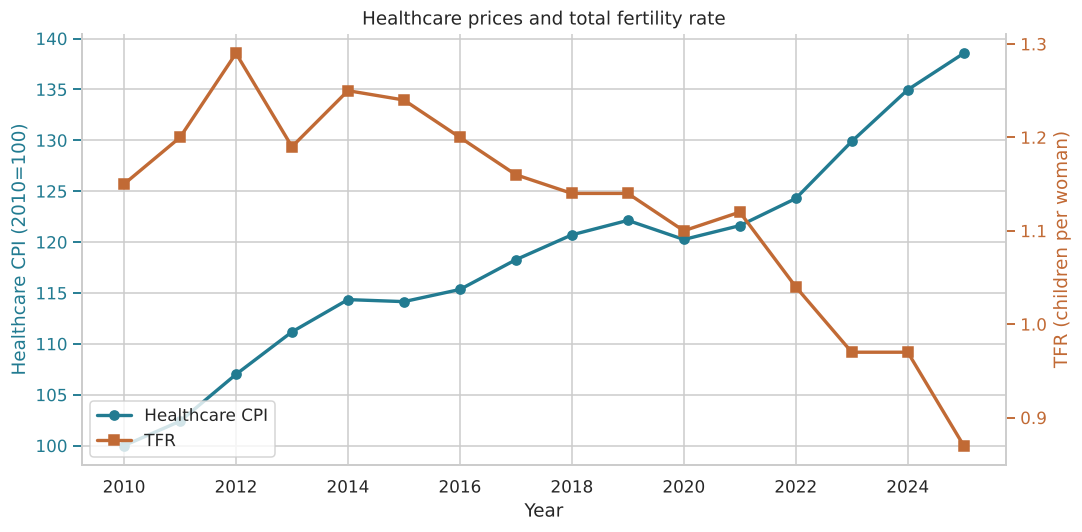

In [7]:
fig, ax = plt.subplots(figsize=(10,5))
other=ax.twinx()
a=ax.plot(df.index,df.cpi_health_2010_100,color='#227b91',marker='o',lw=2.2,label='Healthcare CPI')
b=other.plot(df.index,df.tfr_per_female,color='#c16a35',marker='s',lw=2.2,label='TFR')
ax.set(xlabel='Year',ylabel='Healthcare CPI (2010=100)',title='Healthcare prices and total fertility rate')
other.set_ylabel('TFR (children per woman)',color='#c16a35')
ax.yaxis.label.set_color('#227b91'); ax.tick_params(axis='y',colors='#227b91')
other.tick_params(axis='y',colors='#c16a35'); other.grid(False)
other.spines['right'].set_visible(True)
ax.set_xticks(df.index[::2]); ax.legend(a+b,[x.get_label() for x in a+b],loc='lower left')
show_chart('01_cpi_tfr_comparison')
cpi=df.cpi_health_2010_100.dropna(); tfr=df.tfr_per_female.dropna()


**Finding.** Healthcare CPI rose from 100.00 in 2010 to 138.55 in 2025, while TFR fell from 1.15 to 0.87. These are concurrent long-run patterns(Healthcare CPI is risng and the TFR decreasing).

## Figure 2 — Bar chart: household healthcare spending

**Question:** How much did households spend on healthcare in the observed survey years?

Bar height is monthly spending in nominal SGD. Labels also show its share of household spending. The three bars are separate survey waves, not consecutive annual observations.

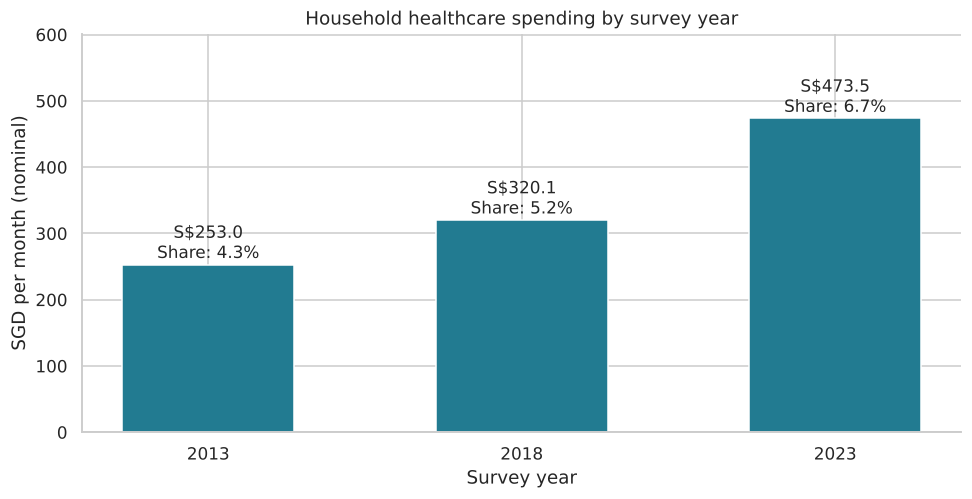

In [8]:
amount='hes_all_households_health_monthly_sgd'
share='hes_all_households_health_share_pct'
waves=df[[amount,share]].dropna()
fig,ax=plt.subplots(figsize=(9,4.7))
bars=ax.bar(waves.index.astype(str),waves[amount],color='#227b91',width=.55)
for bar,(year,row) in zip(bars,waves.iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+10,
            f'S${row[amount]:,.1f}\nShare: {row[share]:.1f}%',ha='center',fontsize=11)
ax.set_ylim(0,waves[amount].max()*1.27)
ax.set(title='Household healthcare spending by survey year',xlabel='Survey year',ylabel='SGD per month (nominal)')
show_chart('02_household_healthcare_spending')
growth=(waves[amount].iloc[-1]/waves[amount].iloc[0]-1)*100
pp=waves[share].iloc[-1]-waves[share].iloc[0]


**Finding.** Monthly household healthcare spending increased from 253.0 in 2013 to 473.5 in 2023, an increase of 87.2%. Its share of household spending rose from 4.3% to 6.7%, or 2.4 percentage points. 

## Figure 3 — Scatter plots: healthcare CPI–TFR correlation

Each point is one year, coloured by year. The left panel compares original levels; the right compares **annual absolute changes**, calculated only for adjacent calendar years. The dashed line is a descriptive linear fit, and Pearson r measures linear association (−1 to +1). The second panel checks whether the level association persists when looking at changes. 

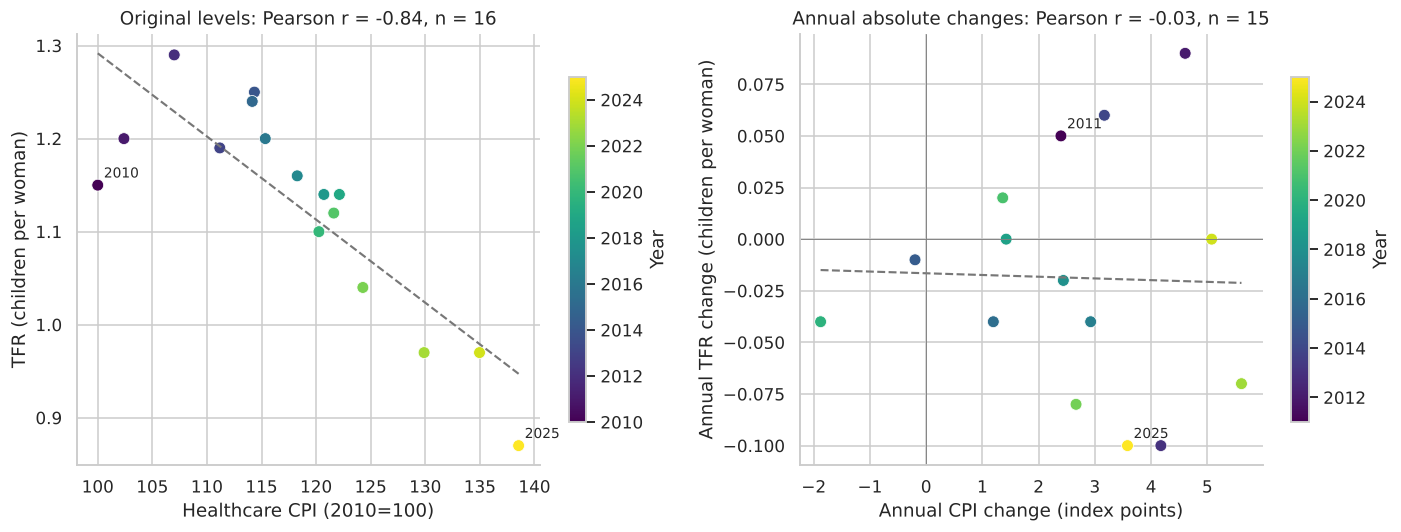

In [9]:
pair=df[['cpi_health_2010_100','tfr_per_female']].dropna()
changes=df[['cpi_health_2010_100','tfr_per_female']].diff().dropna()
fig,axes=plt.subplots(1,2,figsize=(13,5))
correlations=[]
for ax,table,title,xlabel,ylabel in [
    (axes[0],pair,'Original levels','Healthcare CPI (2010=100)','TFR (children per woman)'),
    (axes[1],changes,'Annual absolute changes','Annual CPI change (index points)','Annual TFR change (children per woman)')]:
    x=table.iloc[:,0]; y=table.iloc[:,1]
    r=x.corr(y) if len(table)>=3 and x.nunique()>1 and y.nunique()>1 else np.nan
    dots=ax.scatter(x,y,c=table.index,cmap='viridis',s=60,edgecolor='white',linewidth=.5)
    if len(table)>=3 and x.nunique()>1:
        slope,intercept=np.polyfit(x,y,1)
        xx=np.linspace(x.min(),x.max(),100)
        ax.plot(xx,slope*xx+intercept,color='#777777',ls='--',lw=1.4)
    for year in [table.index.min(),table.index.max()]:
        ax.annotate(str(year),(table.loc[year].iloc[0],table.loc[year].iloc[1]),xytext=(4,5),textcoords='offset points',fontsize=9)
    ax.set(title=f'{title}: Pearson r = {r:.2f}, n = {len(table)}',xlabel=xlabel,ylabel=ylabel)
    fig.colorbar(dots,ax=ax,label='Year',shrink=.8)
    correlations.append({'comparison':title,'n':len(table),'pearson_r':r})
axes[1].axhline(0,color='grey',lw=.6); axes[1].axvline(0,color='grey',lw=.6)
show_chart('03_cpi_tfr_scatter')
pd.DataFrame(correlations).to_csv(OUT/'cpi_tfr_correlations.csv',index=False)


**Finding.** Healthcare CPI and TFR have a Pearson correlation of approximately −0.84 in levels (16 years), compared with −0.03 in annual absolute changes (15 pairs). The contrast suggests that the level association is sensitive to shared time trends. 

## Figure 4 — Box plot: annual healthcare price changes

**Question:** How did annual price changes vary across selected healthcare categories?

YoY = 100 × (this year's index / previous year's index − 1). Only adjacent observed calendar years are used. Each dot represents one year, the box covers the middle 50% of observations, and the line inside is the median. Whiskers follow the 1.5×IQR rule; all observations are shown as dots.

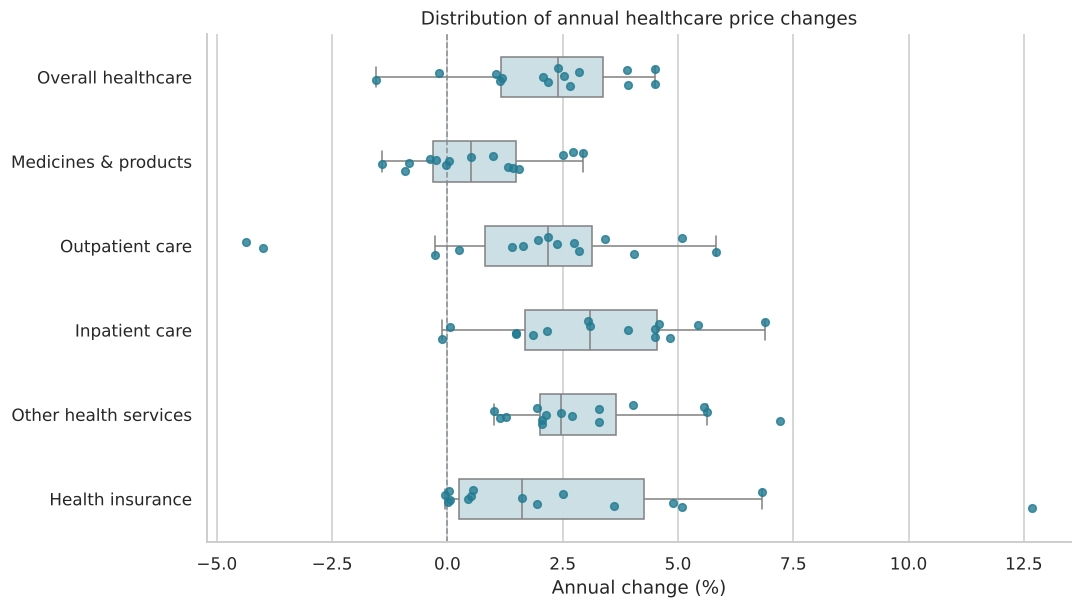

In [10]:
price_labels={'cpi_health_2010_100':'Overall healthcare',
              'cpi_medicines_health_products_2010_100':'Medicines & products',
              'cpi_outpatient_care_2010_100':'Outpatient care',
              'cpi_inpatient_care_2010_100':'Inpatient care',
              'cpi_other_health_services_2010_100':'Other health services',
              'cpi_health_insurance_2010_100':'Health insurance'}
prices=df[list(price_labels)]
yoy=prices.div(prices.shift(1).replace(0,np.nan)).sub(1).mul(100)
plot_data=yoy.rename(columns=price_labels).melt(var_name='Category',value_name='Annual change (%)').dropna()
fig,ax=plt.subplots(figsize=(10,5.7))
sns.boxplot(data=plot_data,x='Annual change (%)',y='Category',color='#c7e1e8',showfliers=False,width=.48,ax=ax)
# Deterministic dot positions: one dot per observed annual change.
for i,(c,name) in enumerate(price_labels.items()):
    vals=yoy[c].dropna()
    ax.scatter(vals,np.full(len(vals),i)+np.linspace(-.11,.11,len(vals)),color='#227b91',s=25,alpha=.8,zorder=3)
ax.axvline(0,color='#858e96',linestyle='--',linewidth=1)
ax.set_title('Distribution of annual healthcare price changes')
ax.set_ylabel(''); show_chart('04_annual_price_change_distribution')
overall=yoy['cpi_health_2010_100'].dropna()
insurance=yoy['cpi_health_insurance_2010_100'].dropna()
yoy.to_csv(OUT/'annual_price_changes.csv',index_label='year')
assert yoy.iloc[0].isna().all()
assert not (prices.shift(1).isna() & yoy.notna()).any().any()


**Finding.** Medicines and health products generally show smaller annual price changes than inpatient care. Outpatient care includes years of price declines. Health insurance has a wide range of annual changes, including a 12.68% increase in 2025. 

## Figure 5 — Area charts: government healthcare expenditure

Three separate panels show **total expenditure**, **per-capita expenditure** and **expenditure as a share of GDP**. These describe scale, spending per person and spending relative to the economy. Each panel uses a zero baseline and its own unit; shaded areas are not cumulative totals or additive components.

All three supplied series end in 2023. No 2024–2025 values are imputed. 

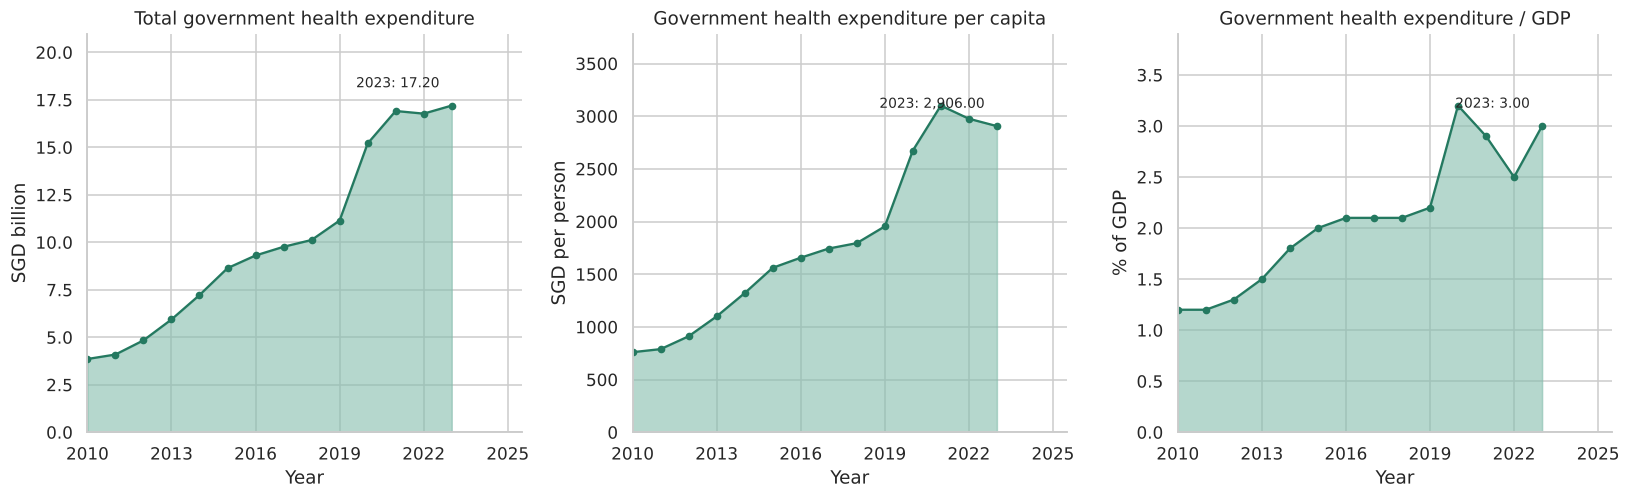

,metric,unit,first_year,first_value,latest_year,latest_value
0,gov_health_expenditure_sgd_million,SGD billion,2010,3.8567,2023,17.199
1,gov_health_per_capita_sgd,SGD per person,2010,760.0000,2023,2906.000
2,gov_health_expenditure_gdp_pct,% of GDP,2010,1.2000,2023,3.000


Completed: five figures, with code and interpretations in this notebook.


In [11]:
government={
    'gov_health_expenditure_sgd_million':('Total government health expenditure','SGD billion',1000),
    'gov_health_per_capita_sgd':('Government health expenditure per capita','SGD per person',1),
    'gov_health_expenditure_gdp_pct':('Government health expenditure / GDP','% of GDP',1)
}
fig,axes=plt.subplots(1,3,figsize=(15,4.7))
gov_rows=[]
for ax,(c,(title,unit,scale)) in zip(axes,government.items()):
    series=df[c]/scale; valid=series.dropna()
    ax.fill_between(series.index,series.to_numpy(),0,color='#85bdad',alpha=.6)
    ax.plot(series.index,series,color='#247960',marker='o',ms=4)
    ax.set(title=title,ylabel=unit,xlabel='Year',ylim=(0,valid.max()*1.22))
    ax.set_xticks(df.index[::3]); ax.set_xlim(df.index.min(),df.index.max()+.5)
    yr=valid.index[-1]
    ax.annotate(f'{yr}: {valid.iloc[-1]:,.2f}',(yr,valid.iloc[-1]),xytext=(-8,12),textcoords='offset points',ha='right',fontsize=9)
    gov_rows.append({'metric':c,'unit':unit,'first_year':valid.index[0],'first_value':valid.iloc[0],
                     'latest_year':yr,'latest_value':valid.iloc[-1]})
show_chart('05_government_healthcare_expenditure')
gov_summary=pd.DataFrame(gov_rows)
display(gov_summary)
gov_summary.to_csv(OUT/'government_healthcare_summary.csv',index=False)
total=df.gov_health_expenditure_sgd_million.dropna()
percap=df.gov_health_per_capita_sgd.dropna()
share=df.gov_health_expenditure_gdp_pct.dropna()
assert len(list(government))==3
print('Completed: five figures, with code and interpretations in this notebook.')


**Finding** Government healthcare expenditure increased from 3.86 billion in 2010 to 17.20 billion in 2023. Per-capita expenditure increased from 760 to 2,906, while spending as a share of GDP rose from 1.2% to 3.0%. 

## Summary

Healthcare prices, household spending and government expenditure increased over their observed periods. TFR generally declined. The CPI–TFR correlation is strongly negative in levels but close to zero in annual changes, so the level association should not be treated as evidence of causation.

There are at most 16 annual observations, three household survey waves and different end years across indicators. Monetary values are nominal. Government expenditure about healthcare cannot cover the rising healthcare costs, and the expenditure willing of the government is not too "strong".